# 17 · NLP & Large Language Models — From Tokens to a Tiny GPT

This notebook goes from raw text to the core ideas behind ChatGPT-style models, building every piece small enough to run on a laptop CPU:

**What you'll learn**
1. **Tokenisation:** words vs characters vs **subwords** — byte-pair encoding (BPE) built 🐍 from scratch, then with 📦 Hugging Face `tokenizers`
2. Classic text representations: **TF-IDF** and **BM25** search
3. **Word embeddings** from co-occurrence statistics (PPMI + SVD) — "you shall know a word by the company it keeps"
4. **Language models** and **perplexity**: an n-gram model from scratch
5. **A tiny GPT**: a decoder-only transformer trained from scratch on ~500k characters
6. **Decoding:** greedy, temperature, top-k and top-p (nucleus) sampling
7. How real LLMs are built: scaling, pretraining → instruction tuning → RLHF, prompting
8. LLM engineering: **KV cache**, **LoRA** fine-tuning, **quantisation**
9. **Retrieval-augmented generation (RAG)** — retrieval, evaluation, prompt assembly
10. Evaluating LLMs, and their failure modes

**Data.** Offline, via `text_data.py`: ~490k characters of Python's standard-library documentation (technical English), plus the synthetic product reviews from notebook 16.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, time, random, re
from collections import Counter, defaultdict
import torch
from torch import nn
import torch.nn.functional as F
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); torch.manual_seed(0); random.seed(0)

from text_data import load_corpus, make_reviews
corpus = load_corpus()
print(f"{len(corpus):,} characters, {len(corpus.split()):,} words")
print(corpus[2000:2400])

488,186 characters, 75,087 words
re are seven 'a'
7
>>> del c['b'] # remove all 'b'
>>> c['b'] # now there are zero 'b'
0

>>> d = Counter('simsalabim') # make another counter
>>> c.update(d) # add in the second counter
>>> c['a'] # now there are nine 'a'
9

>>> c.clear() # empty the counter
>>> c
Counter()

Note: If a count is set to zero or reduced to zero, it will remain
in the counter until the entry is deleted or the counter


## 1. Tokenisation — turning text into integers

Models work on numbers, so text must be split into **tokens**, each mapped to an integer ID. Three choices:

| Unit | Vocabulary | Sequence length | Unknown words? |
|---|---|---|---|
| **Words** | huge (every word form: "run", "runs", "running"…) | short | yes — new words become `[UNK]` |
| **Characters** | tiny (~100) | very long | never |
| **Subwords** (BPE, WordPiece, Unigram) | chosen, e.g. 32k–200k | medium | never — rare words split into known pieces |

Modern LLMs use **subwords**: common words stay whole, rare words split into meaningful pieces ("tokenization" → "token" + "ization").

### Byte-pair encoding (BPE), from scratch
1. Start with every word split into characters (plus an end-of-word marker).
2. Count every pair of adjacent symbols across the corpus.
3. **Merge the most frequent pair** into a new symbol. Record the merge.
4. Repeat until the vocabulary is the size you want.

To tokenise new text, apply the learned merges in the same order.

In [2]:
# 🐍 Pure Python BPE training
def train_bpe(text, n_merges=500):
    word_freq = Counter(re.findall(r"\w+|[^\w\s]", text.lower()))
    words = {w: list(w) + ["</w>"] for w in word_freq}                   # each word as a list of symbols
    merges = []
    for _ in range(n_merges):
        pairs = Counter()
        for w, syms in words.items():
            for a, b in zip(syms, syms[1:]):
                pairs[(a, b)] += word_freq[w]
        if not pairs: break
        best = max(pairs, key=pairs.get)                                  # most frequent adjacent pair
        merges.append(best)
        for w, syms in words.items():                                     # apply the merge everywhere
            i, out = 0, []
            while i < len(syms):
                if i < len(syms) - 1 and (syms[i], syms[i + 1]) == best:
                    out.append(syms[i] + syms[i + 1]); i += 2
                else:
                    out.append(syms[i]); i += 1
            words[w] = out
    return merges

def bpe_encode(word, merges):
    syms = list(word.lower()) + ["</w>"]
    for a, b in merges:                                                   # replay merges in training order
        i, out = 0, []
        while i < len(syms):
            if i < len(syms) - 1 and syms[i] == a and syms[i + 1] == b:
                out.append(a + b); i += 2
            else:
                out.append(syms[i]); i += 1
        syms = out
    return syms

t0 = time.perf_counter(); merges = train_bpe(corpus[:200_000], n_merges=500)
print(f"learned {len(merges)} merges in {time.perf_counter() - t0:.1f}s; first ten: {merges[:10]}")
for w in ["the", "function", "returns", "tokenization", "unbelievably", "Pythonic"]:
    print(f"{w:13s} → {bpe_encode(w, merges)}")

learned 500 merges in 3.0s; first ten: [('e', '</w>'), ('s', '</w>'), ('t', 'h'), ('t', '</w>'), ('i', 'n'), ('.', '</w>'), ('d', '</w>'), ('e', 'r'), ('n', '</w>'), (',', '</w>')]
the           → ['the</w>']
function      → ['function</w>']
returns       → ['returns</w>']
tokenization  → ['to', 'k', 'en', 'i', 'z', 'ation</w>']
unbelievably  → ['un', 'be', 'li', 'e', 'v', 'ab', 'ly</w>']
Pythonic      → ['pyth', 'on', 'i', 'c</w>']


In [3]:
# 📦 Hugging Face `tokenizers` — the same algorithm in Rust, used by many real models
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
hf_tok = Tokenizer(models.BPE(unk_token="[UNK]")); hf_tok.pre_tokenizer = pre_tokenizers.Whitespace()
t0 = time.perf_counter()
hf_tok.train_from_iterator(corpus.split("\n\n"), trainers.BpeTrainer(vocab_size=2000, special_tokens=["[UNK]"], show_progress=False))
print(f"trained a 2,000-token BPE vocabulary on the whole corpus in {time.perf_counter() - t0:.2f}s")
sentence = "The tokenizer splits unbelievably rare words into subword pieces."
print(hf_tok.encode(sentence).tokens)

words = corpus.split()
for vocab_size in [500, 2000, 8000]:
    tk = Tokenizer(models.BPE(unk_token="[UNK]")); tk.pre_tokenizer = pre_tokenizers.Whitespace()
    tk.train_from_iterator(corpus.split("\n\n"), trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"], show_progress=False))
    n_tok = sum(len(e.tokens) for e in tk.encode_batch(corpus.split("\n\n")[:500]))
    n_words = sum(len(p.split()) for p in corpus.split("\n\n")[:500])
    print(f"vocab {vocab_size:5d}: {n_tok / n_words:.2f} tokens per word")

trained a 2,000-token BPE vocabulary on the whole corpus in 0.14s
['The', 'token', 'i', 'zer', 'sp', 'l', 'its', 'un', 'be', 'li', 'ev', 'ab', 'ly', 'r', 'are', 'words', 'into', 'sub', 'word', 'pi', 'ec', 'es', '.']
vocab   500: 2.48 tokens per word


vocab  2000: 1.72 tokens per word


vocab  8000: 1.38 tokens per word


A bigger vocabulary means shorter sequences, so more text fits in the context window, but larger embedding tables. Tokenisation explains some famous LLM quirks: they're bad at counting letters (they don't *see* letters, only tokens), arithmetic suffers when numbers split oddly ("12345" → "123" + "45"), and non-English text often costs more tokens for the same content.

## 2. Classic representations: TF-IDF and BM25

Before neural networks, text was represented as **sparse vectors of word weights** — and it's still a strong baseline for search.

**TF-IDF** = term frequency × inverse document frequency:
$$ \text{tfidf}(w, d) = \text{tf}(w, d) \cdot \log\frac{N}{\text{df}(w)} $$
A word gets a high weight in a document if it's frequent **there** but rare **overall** ("sqlite" beats "the"). Compare documents with cosine similarity (notebook 14).

**BM25** improves TF-IDF for search: term frequency **saturates** (the 10th "sqlite" adds less than the 2nd) and long documents are normalised. It's the default in search engines like Elasticsearch.

In [4]:
paragraphs = [p.strip() for p in corpus.split("\n\n") if len(p.split()) >= 8]
tokenize = lambda s: re.findall(r"[a-z0-9]+", s.lower())
docs_tok = [tokenize(p) for p in paragraphs]
print(f"{len(paragraphs):,} paragraphs to search")

# 🐍 Pure Python BM25
class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.docs, self.k1, self.b = docs, k1, b
        self.N = len(docs); self.avgdl = sum(map(len, docs)) / self.N
        self.df = Counter(w for d in docs for w in set(d))
        self.tf = [Counter(d) for d in docs]
    def idf(self, w):
        return math.log(1 + (self.N - self.df[w] + 0.5) / (self.df[w] + 0.5))
    def scores(self, query):
        q = tokenize(query); out = []
        for tf, d in zip(self.tf, self.docs):
            s = 0.0
            for w in q:
                f = tf[w]
                s += self.idf(w) * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * len(d) / self.avgdl))
            out.append(s)
        return np.array(out)

bm25 = BM25(docs_tok)

# 📦 scikit-learn TF-IDF + cosine similarity
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(token_pattern=r"[a-z0-9]+", sublinear_tf=True).fit(paragraphs)
D = tfidf.transform(paragraphs)
def tfidf_scores(query): return (D @ tfidf.transform([query]).T).toarray().ravel()

q = "create a temporary directory"
for name, fn in [("BM25 (ours)", bm25.scores), ("TF-IDF (sklearn)", tfidf_scores)]:
    top = np.argsort(-fn(q))[:2]
    print(f"\n{name} — top results for {q!r}:")
    for i in top: print("   •", paragraphs[i][:110].replace("\n", " "))

2,519 paragraphs to search



BM25 (ours) — top results for 'create a temporary directory':
   • User-callable function to create and return a unique temporary directory. The return value is the pathname of 
   • Create and return a temporary directory. This has the same behavior as mkdtemp but can be used as a context ma

TF-IDF (sklearn) — top results for 'create a temporary directory':
   • User-callable function to create and return a unique temporary directory. The return value is the pathname of 
   • Create and return a temporary directory. This has the same behavior as mkdtemp but can be used as a context ma


## 3. Word embeddings: meaning from context

Sparse vectors treat "file" and "files", or "error" and "exception", as unrelated. **Embeddings** give each word a dense vector so that words used in similar **contexts** get similar vectors — the **distributional hypothesis**.

The classic recipe (closely related to word2vec and GloVe):
1. Count how often each word appears near each other word (a window of ±4 words) → co-occurrence matrix.
2. Convert counts to **PPMI** (positive pointwise mutual information): $\max\!\left(0, \log\frac{P(w, c)}{P(w)P(c)}\right)$ — "do these words co-occur *more than chance*?"
3. Compress with a truncated **SVD** (notebook 14) → each word becomes a 100-dimensional vector.

In [5]:
# 🐍 Pure Python co-occurrence counting
all_tokens = tokenize(corpus)
vocab = [w for w, c in Counter(all_tokens).most_common(4000)]
w2i = {w: i for i, w in enumerate(vocab)}
cooc = defaultdict(float); window = 4
for i, w in enumerate(all_tokens):
    if w not in w2i: continue
    for j in range(max(0, i - window), min(len(all_tokens), i + window + 1)):
        if j != i and all_tokens[j] in w2i:
            cooc[(w2i[w], w2i[all_tokens[j]])] += 1.0 / abs(i - j)          # closer words count more

# 🔢 NumPy: PPMI matrix
V = len(vocab); C = np.zeros((V, V))
for (a, b_), v in cooc.items(): C[a, b_] = v
total = C.sum(); pw = C.sum(1, keepdims=True) / total; pc = C.sum(0, keepdims=True) / total
with np.errstate(divide="ignore", invalid="ignore"):
    pmi = np.log((C / total) / (pw * pc))
ppmi = np.nan_to_num(np.maximum(pmi, 0))

# 📦 scikit-learn TruncatedSVD → 100-d embeddings
from sklearn.decomposition import TruncatedSVD
E = TruncatedSVD(100, random_state=0).fit_transform(ppmi)
E /= np.linalg.norm(E, axis=1, keepdims=True) + 1e-9                    # unit length → dot product = cosine

def neighbours(word, k=6):
    sims = E @ E[w2i[word]]
    return [vocab[j] for j in np.argsort(-sims)[1:k + 1]]
for w in ["file", "error", "thread", "string", "list", "true", "read", "server"]:
    print(f"{w:8s} → {neighbours(w)}")

file     → ['descriptor', 'mode', 'fd', 'opened', 'env', 'src']
error    → ['errors', 'linenumber', 'occurred', 'abort', 'occurs', 'exception']
thread   → ['reentrant', 'acquired', 'unlock', 'attempting', 'currentthread', 'lock']
string   → ['ascii', 'containing', 'octdigits', 'uppercase', 'punctuation', 'ailmsux']
list     → ['sorted', 'former', 'of', 'easier', 'userstring', 'userlist']
true     → ['false', 'hyphenated', 'if', 'wexitstatus', 'wifsignaled', 'default']
read     → ['headers', 'putrequest', 'putheader', 'endheaders', 'unread', 'response']
server   → ['service', 'imap4', 'ssl', 'smtp', 'addr', 'port']


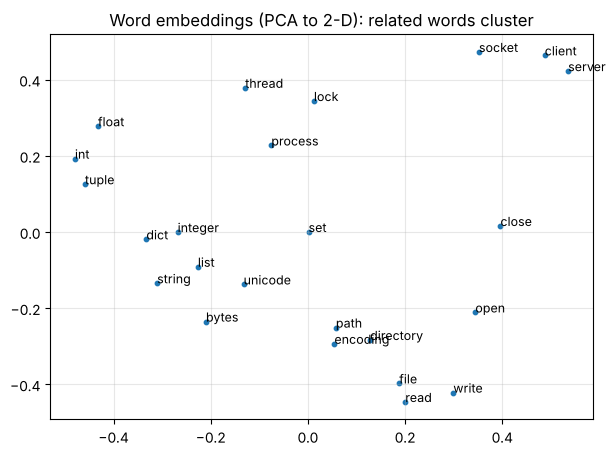

In [6]:
# Visualise a few words in 2-D (PCA of their embeddings)
from sklearn.decomposition import PCA
show = ["file", "directory", "path", "read", "write", "open", "close", "thread", "process", "lock", "socket", "server",
        "client", "string", "bytes", "unicode", "encoding", "int", "float", "integer", "list", "tuple", "dict", "set"]
show = [w for w in show if w in w2i]
P2 = PCA(2).fit_transform(E[[w2i[w] for w in show]])
plt.figure(figsize=(7, 5)); plt.scatter(*P2.T, s=10)
for (x_, y_), w in zip(P2, show): plt.text(x_, y_, w, fontsize=9)
plt.title("Word embeddings (PCA to 2-D): related words cluster"); plt.show()

**word2vec** (2013) learns similar vectors by training a tiny network to predict context words (skip-gram) — implemented in `nlp_from_scratch.py`. These vectors are **static**: "bank" gets one vector whether it's a river bank or a money bank. **Contextual embeddings** from transformers (BERT, GPT) fix that — each token's vector depends on the whole sentence. Modern **sentence embeddings** (used in semantic search and RAG) are produced by transformer encoders trained so that similar meanings get similar vectors.

## 4. Language models and perplexity

A **language model** assigns probabilities to text by predicting the next token from the previous ones:
$$ P(w_1, \dots, w_n) = \prod_{t} P(w_t \mid w_1, \dots, w_{t-1}) $$
Every LLM — GPT, Claude, Llama — is trained on exactly this objective: **predict the next token**, minimising cross-entropy (log-loss, notebook 02).

**Perplexity** = $\exp(\text{average cross-entropy})$ — "how many choices the model is effectively hesitating between". Lower is better. A uniform guess over V characters has perplexity V.

### An n-gram model, from scratch
Estimate $P(\text{next char} \mid \text{previous } n-1 \text{ chars})$ by counting. With **add-k smoothing** for unseen combinations.

In [7]:
chars = sorted(set(corpus)); stoi = {c: i for i, c in enumerate(chars)}; itos = {i: c for c, i in stoi.items()}
split = int(0.9 * len(corpus)); train_text, val_text = corpus[:split], corpus[split:]
print(f"character vocabulary: {len(chars)} | uniform-guess perplexity = {len(chars)}")

# 🐍 Pure Python character n-gram model
class CharNGram:
    def __init__(self, n, k=0.1):
        self.n, self.k = n, k; self.counts = defaultdict(Counter)
    def fit(self, text):
        pad = "\n" * (self.n - 1) + text
        for i in range(self.n - 1, len(pad)):
            self.counts[pad[i - self.n + 1:i]][pad[i]] += 1
        return self
    def prob(self, context, ch):
        c = self.counts.get(context[-(self.n - 1):] if self.n > 1 else "", Counter())
        return (c[ch] + self.k) / (sum(c.values()) + self.k * len(chars))
    def perplexity(self, text):
        pad = "\n" * (self.n - 1) + text; nll = 0.0
        for i in range(self.n - 1, len(pad)):
            nll -= math.log(self.prob(pad[i - self.n + 1:i], pad[i]))
        return math.exp(nll / len(text))
    def generate(self, prompt, length, seed=0):
        r = random.Random(seed); out = prompt
        for _ in range(length):
            ctx = out[-(self.n - 1):] if self.n > 1 else ""
            c = self.counts.get(ctx)
            out += r.choices(list(c), weights=list(c.values()))[0] if c else r.choice(chars)
        return out

ngram_ppl = {}
for n in [1, 2, 3, 5, 8]:
    m_ = CharNGram(n).fit(train_text); ngram_ppl[n] = m_.perplexity(val_text[:20000])
    print(f"{n}-gram: validation perplexity {ngram_ppl[n]:6.2f}")
print("\n5-gram sample:\n", CharNGram(5).fit(train_text).generate("Return the ", 250))

character vocabulary: 97 | uniform-guess perplexity = 97
1-gram: validation perplexity  26.03


2-gram: validation perplexity  13.79


3-gram: validation perplexity   8.00


5-gram: validation perplexity   6.83


8-gram: validation perplexity  19.76



5-gram sample:
 Return the method
 secreted(task() yield-inform is passert always can be True of the destroyed.

Has the FTP client in returned in bytes like generator input", an instance
 integer, as impletes of multiple counts.

The coroutinesep. If an it copytree(), getopt 


Longer contexts help — until they don't: the 8-gram has seen most 7-character contexts only a handful of times (or never), so its estimates are unreliable and smoothing hurts. Counting can't **generalise** between similar contexts. Neural language models solve this by learning *representations* of the context.

## 5. A tiny GPT, from scratch

A **GPT** (generative pre-trained transformer) is a stack of **decoder** transformer blocks (notebook 16) with a **causal mask**, trained to predict the next token at every position at once. Ours is character-level: ~630k parameters, 3 layers, a context of 96 characters. (GPT-3 has 175 billion parameters, 96 layers and a 2,048-token context — the same architecture, scaled up.)

In [8]:
data = torch.tensor([stoi[c] for c in corpus]); train_data, val_data = data[:split], data[split:]
BLOCK = 96                                                     # context length

def get_batch(d, batch_size=32, gen=None):
    ix = torch.randint(len(d) - BLOCK - 1, (batch_size,), generator=gen)
    x = torch.stack([d[i:i + BLOCK] for i in ix]); y = torch.stack([d[i + 1:i + BLOCK + 1] for i in ix])   # targets = inputs shifted by one
    return x, y

class CausalSelfAttention(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.qkv = nn.Linear(d, 3 * d)                         # queries, keys, values in one matrix
        self.proj = nn.Linear(d, d)
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        q, k, v = [z.view(B, T, self.n_heads, C // self.n_heads).transpose(1, 2) for z in (q, k, v)]   # (B, heads, T, d_head)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)                                     # masked attention
        return self.proj(y.transpose(1, 2).reshape(B, T, C))

class Block(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = CausalSelfAttention(d, n_heads)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class TinyGPT(nn.Module):
    def __init__(self, vocab, d=128, n_heads=4, n_layers=3, block=BLOCK):
        super().__init__()
        self.tok = nn.Embedding(vocab, d); self.pos = nn.Embedding(block, d)
        self.blocks = nn.Sequential(*[Block(d, n_heads) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d); self.head = nn.Linear(d, vocab, bias=False)
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        return self.head(self.ln(self.blocks(x)))              # logits for the next token at every position

    @torch.no_grad()
    def generate(self, prompt, n_new, temperature=0.8, top_k=None, top_p=None, seed=0):
        g = torch.Generator().manual_seed(seed)
        idx = torch.tensor([[stoi[c] for c in prompt]])
        for _ in range(n_new):
            logits = self(idx[:, -BLOCK:])[0, -1] / temperature
            probs = filter_probs(F.softmax(logits, -1), top_k, top_p)
            idx = torch.cat([idx, torch.multinomial(probs, 1, generator=g)[None]], 1)
        return "".join(itos[i] for i in idx[0].tolist())

def filter_probs(probs, top_k=None, top_p=None):
    if top_k is not None:                                       # keep only the k most likely tokens
        kth = torch.topk(probs, top_k).values[-1]; probs = torch.where(probs >= kth, probs, 0)
    if top_p is not None:                                       # keep the smallest set whose total probability ≥ p
        sp, si = torch.sort(probs, descending=True); keep = torch.cumsum(sp, 0) - sp < top_p
        mask = torch.zeros_like(probs, dtype=torch.bool); mask[si[keep]] = True; probs = torch.where(mask, probs, 0)
    return probs / probs.sum()

@torch.no_grad()
def val_loss(model, n_batches=20):
    model.eval(); g = torch.Generator().manual_seed(123)            # its own generator: the same validation batches every time,
    out = np.mean([F.cross_entropy(model(x).reshape(-1, len(chars)), y.reshape(-1)).item()   # without disturbing training's randomness
                   for x, y in [get_batch(val_data, gen=g) for _ in range(n_batches)]])
    model.train(); return out

torch.manual_seed(0)
gpt = TinyGPT(len(chars))
print(f"parameters: {sum(p.numel() for p in gpt.parameters()):,}")
print("before training:", repr(gpt.generate("Return the ", 80)))

parameters: 632,192


before training: 'Return the X9W/N,K=@@gP<h9Z7Hu2V9pHD4E8UE(oG9d`3\x00/5BF,;$n6ZBFG-zt|-l)Id(Z+9dWXUy)nWzq?}9{uC'


trained 1500 steps in 132s


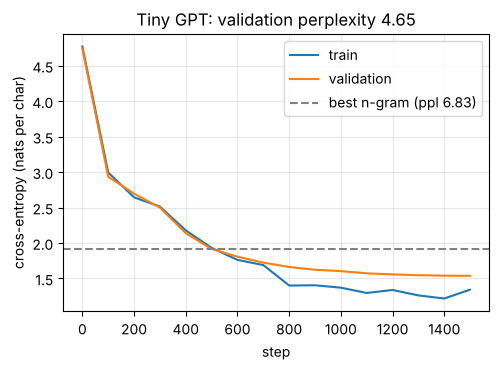

In [9]:
steps = 1500
opt = torch.optim.AdamW(gpt.parameters(), lr=3e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=steps)   # warm-up then decay
history = []; t0 = time.perf_counter()
for step in range(steps):
    x, y = get_batch(train_data)
    loss = F.cross_entropy(gpt(x).reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(gpt.parameters(), 1.0); opt.step(); sched.step()
    if step % 100 == 0 or step == steps - 1:
        history.append((step, loss.item(), val_loss(gpt)))
print(f"trained {steps} steps in {time.perf_counter() - t0:.0f}s")
gpt_ppl = math.exp(history[-1][2])
plt.plot([h[0] for h in history], [h[1] for h in history], label="train"); plt.plot([h[0] for h in history], [h[2] for h in history], label="validation")
plt.axhline(math.log(min(ngram_ppl.values())), ls="--", c="gray", label=f"best n-gram (ppl {min(ngram_ppl.values()):.2f})")
plt.xlabel("step"); plt.ylabel("cross-entropy (nats per char)"); plt.legend(); plt.title(f"Tiny GPT: validation perplexity {gpt_ppl:.2f}"); plt.show()

In [10]:
print(gpt.generate("Return the ", 400, temperature=0.8))

Return the heap and code by defined with an address to
only.

Extending in the loggers of the last of the file together every.

Note the file for class float seconds directory to recursive directory.

A file descriptor information be quarity to whole the returned
to a UUID an argument of stream. The number of the version
simple is cancelled filenamed by and the newline integer.

StreamReader of SIG is None t


After two minutes on a CPU, the model has learned spelling, punctuation, the rhythm of docstrings and code-like fragments — with no understanding at all. Scale the same recipe by ~10⁶× in parameters and data, and the model starts to show the abilities of modern LLMs.

## 6. Decoding — how to pick the next token

The model outputs a probability for every token. How we choose from it changes the text a lot:

| Strategy | Rule | Character |
|---|---|---|
| **Greedy** | always the most likely | deterministic; tends to repeat itself |
| **Temperature T** | sample from softmax(logits / T) | T < 1 sharper/safer; T > 1 flatter/more random |
| **Top-k** | sample only among the k most likely | cuts the long tail of nonsense |
| **Top-p (nucleus)** | sample among the smallest set with total probability ≥ p | adapts: few options when confident, many when unsure |
| **Beam search** | keep the best few partial sequences | good for translation; bland for open-ended text |

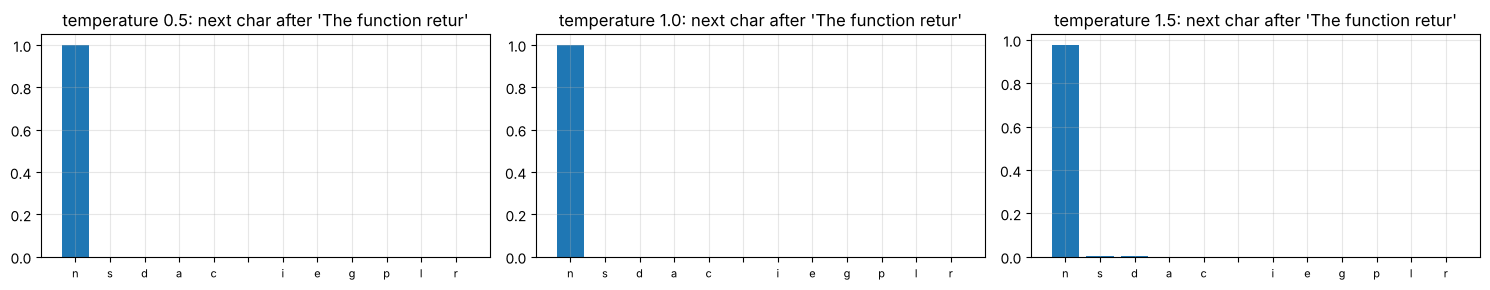

--- greedy (T→0)
'If the file descriptor is a string of the string of the strings are all the strings are\nallow interpreter in the context manager is a string a string of the context manager'



--- T = 0.8
'If the file descriptor mories\nas on should be relative; the slate into next with\nthe size string thread of bytes are called lines of each of a passing\nusing modifies alread'



--- T = 1.5
"If the file name defined with\nconst should the 'l' is argumenly many sbngettwise,\nno-on instance; from for inreaf\n.35-1: 0.0993_1203) 225 4.dr utiftive_creation abovial; in"



--- T = 1.5 + top-k 5
'If the file data strings to than on item token which\nthol the filename.\n\nAscii_uple once, bunding from one.\n\nContax follow set_commosest_dons(let() -> type\n color a tabolic'



--- T = 1.5 + top-p 0.9
'If the file name defined with\nconst should the byte ratoget-slags, list\nremove_txenshow_instatial from for instance.symlinks.\n*y* Unseage of ranther to standard aboviabooin'



In [11]:
with torch.no_grad():
    logits = gpt(torch.tensor([[stoi[c] for c in "The function retur"]]))[0, -1]
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, T in zip(axes, [0.5, 1.0, 1.5]):
    p = F.softmax(logits / T, -1).numpy(); top = np.argsort(-p)[:12]
    ax.bar([repr(itos[i])[1:-1] for i in top], p[top]); ax.set_title(f"temperature {T}: next char after 'The function retur'"); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

for name, kw in [("greedy (T→0)", dict(temperature=0.01)), ("T = 0.8", dict(temperature=0.8)), ("T = 1.5", dict(temperature=1.5)),
                 ("T = 1.5 + top-k 5", dict(temperature=1.5, top_k=5)), ("T = 1.5 + top-p 0.9", dict(temperature=1.5, top_p=0.9))]:
    print(f"--- {name}\n{gpt.generate('If the file ', 160, seed=1, **kw)!r}\n")

## 7. From a tiny GPT to a real LLM

**Scale.** A GPT's parameter count is roughly $12 \cdot L \cdot d^2$ (L layers, width d) plus embeddings. **Scaling laws** (Kaplan et al. 2020; Chinchilla, Hoffmann et al. 2022) found that loss falls smoothly and predictably as a power law in parameters, data and compute — and that for a fixed compute budget, parameters and training tokens should grow together (roughly 20 tokens per parameter for compute-optimal training).

In [12]:
L, d = 3, 128
print(f"our model: 12·L·d² = {12 * L * d * d:,} (+ embeddings {len(chars) * d + BLOCK * d:,}) ≈ actual {sum(p.numel() for p in gpt.parameters()):,}")
for name, L_, d_ in [("GPT-2 small", 12, 768), ("GPT-2 XL", 48, 1600), ("GPT-3", 96, 12288)]:
    print(f"{name:12s} L={L_:3d}, d={d_:6d} → 12·L·d² ≈ {12 * L_ * d_ ** 2 / 1e9:7.2f} billion")

our model: 12·L·d² = 589,824 (+ embeddings 24,704) ≈ actual 632,192
GPT-2 small  L= 12, d=   768 → 12·L·d² ≈    0.08 billion
GPT-2 XL     L= 48, d=  1600 → 12·L·d² ≈    1.47 billion
GPT-3        L= 96, d= 12288 → 12·L·d² ≈  173.95 billion


**The training pipeline** of a chat assistant:
1. **Pretraining:** next-token prediction on trillions of tokens of web text, books and code. The model learns language, facts and patterns, but it's a document *completer*, not an assistant.
2. **Supervised fine-tuning (SFT / instruction tuning):** train on curated (instruction → good response) examples, so it learns to follow requests.
3. **Preference tuning:** humans (or AI feedback) compare pairs of responses. **RLHF** trains a reward model on those comparisons, then optimises the LLM against it with reinforcement learning (PPO). **DPO** optimises directly on the preference pairs, with no separate reward model. This shapes helpfulness, honesty and harmlessness.

**Using LLMs without training them:**
- **Prompting / in-context learning:** describe the task and give a few examples in the prompt; the model adapts without any weight updates.
- **Chain-of-thought:** asking for step-by-step reasoning improves multi-step problems.
- **Tools & agents:** the model calls functions (search, calculators, code execution) and uses the results.
- **RAG** (Section 9): fetch relevant documents and put them in the prompt.

## 8. LLM engineering: KV cache, LoRA, quantisation

### 8.1 The KV cache
When generating token by token, a naive implementation recomputes keys and values for the **whole** prefix at every step. But earlier tokens' K and V never change (the causal mask means they can't see later tokens). **Cache them**: each new step computes K, V for only the newest token. Generation then costs O(n) projections in total instead of O(n²) — at the price of memory that grows with context length (often the bottleneck when serving LLMs).

In [13]:
# 🔢 Single-head attention decoder step: naive vs cached, in NumPy
d = 64; Wq, Wk, Wv = (rng.normal(0, d ** -0.5, (d, d)) for _ in range(3))
def attend(q, K, V):
    s = K @ q / np.sqrt(d); w = np.exp(s - s.max()); w /= w.sum(); return w @ V

def generate_naive(X):
    outs, flops = [], 0
    for t in range(1, len(X) + 1):
        K, V = X[:t] @ Wk, X[:t] @ Wv; flops += 2 * t * d * d       # recompute K, V for the whole prefix
        outs.append(attend(X[t - 1] @ Wq, K, V))
    return np.array(outs), flops

def generate_cached(X):
    outs, flops, K, V = [], 0, np.zeros((0, d)), np.zeros((0, d))
    for t in range(len(X)):
        K = np.vstack([K, X[t] @ Wk]); V = np.vstack([V, X[t] @ Wv]); flops += 2 * d * d   # only the new token
        outs.append(attend(X[t] @ Wq, K, V))
    return np.array(outs), flops

for n in [128, 512, 1024]:
    X = rng.normal(size=(n, d))
    t0 = time.perf_counter(); o1, f1 = generate_naive(X); t1 = time.perf_counter() - t0
    t0 = time.perf_counter(); o2, f2 = generate_cached(X); t2 = time.perf_counter() - t0
    print(f"n={n:5d}: same outputs {np.allclose(o1, o2)} | K/V projection FLOPs naive {f1:.1e} vs cached {f2:.1e} ({f1 / f2:.0f}×) | time {t1:.2f}s vs {t2:.2f}s")

n=  128: same outputs True | K/V projection FLOPs naive 6.8e+07 vs cached 1.0e+06 (64×) | time 0.00s vs 0.00s
n=  512: same outputs True | K/V projection FLOPs naive 1.1e+09 vs cached 4.2e+06 (256×) | time 0.04s vs 0.01s


n= 1024: same outputs True | K/V projection FLOPs naive 4.3e+09 vs cached 8.4e+06 (512×) | time 0.19s vs 0.04s


### 8.2 LoRA — fine-tuning with 3% of the parameters
Full fine-tuning updates every weight — expensive for billions of parameters, and you must store a full copy per task. **LoRA** (low-rank adaptation) freezes the pretrained weight W and learns a small **low-rank update**:
$$ W' = W + \frac{\alpha}{r} BA, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r},\; r \ll d $$
B starts at zero, so training begins exactly at the pretrained model. Only A and B are trained. Below we adapt our docstring-trained GPT to write **product reviews**, training only LoRA adapters on the attention layers.

In [14]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=8, alpha=16):
        super().__init__()
        self.base = base
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.01)
        self.B = nn.Parameter(torch.zeros(base.out_features, r))        # zero → no change at the start
        self.scale = alpha / r
    def forward(self, x):
        return self.base(x) + (x @ self.A.T @ self.B.T) * self.scale

import copy
lora_gpt = copy.deepcopy(gpt)
for p in lora_gpt.parameters(): p.requires_grad = False               # freeze everything…
for blk in lora_gpt.blocks:                                           # …then add trainable adapters
    blk.attn.qkv = LoRALinear(blk.attn.qkv); blk.attn.proj = LoRALinear(blk.attn.proj)
trainable = sum(p.numel() for p in lora_gpt.parameters() if p.requires_grad); total = sum(p.numel() for p in lora_gpt.parameters())
print(f"trainable parameters: {trainable:,} of {total:,} ({trainable / total:.1%})")

reviews_text = "\n".join(make_reviews(3000, seed=5)[0])
review_data = torch.tensor([stoi[c] for c in reviews_text if c in stoi])
opt = torch.optim.AdamW([p for p in lora_gpt.parameters() if p.requires_grad], lr=3e-3)
print("before:", repr(lora_gpt.generate("the ", 90, seed=2)))
for step in range(300):
    x, y = get_batch(review_data)
    loss = F.cross_entropy(lora_gpt(x).reshape(-1, len(chars)), y.reshape(-1)); opt.zero_grad(); loss.backward(); opt.step()
print(f"after 300 LoRA steps (loss {loss.item():.2f}):\n{lora_gpt.generate('the ', 260, seed=2)}")

trainable parameters: 18,432 of 650,624 (2.8%)
before: "the replacing at 'foo/b' integer for\n collections the class are type as interface.\n FileExampl"


after 300 LoRA steps (loss 0.34):
the price the blender is not perfect
honestly the charger is awful but the app is flimsy
overall the case is not useful
honestly the battery is solid
so far the speaker is comfortable
in my opinion the blender is not reliable
after a week the mouse is not terrible


The base model is untouched, so you can keep one base model and swap in a tiny adapter per task. **QLoRA** combines this with a 4-bit quantised base model, so large models can be fine-tuned on a single GPU.

### 8.3 Quantisation — smaller, faster models
Store weights in fewer bits: 32-bit floats → 8-bit integers (4× smaller) or 4 bits (8×). LLM inference is mostly limited by **moving weights from memory**, so smaller weights mean faster generation. Simple symmetric int8 quantisation per output row: $q = \text{round}(w / s)$, $s = \max|w| / 127$; dequantise as $q \cdot s$.

In [15]:
def quantize_rowwise(W, bits=8):
    qmax = 2 ** (bits - 1) - 1
    scale = W.abs().amax(dim=1, keepdim=True).clamp(min=1e-8) / qmax
    return torch.round(W / scale).clamp(-qmax, qmax).to(torch.int8), scale

qgpt = copy.deepcopy(gpt); bytes_fp32 = bytes_q = 0
for name, mod in qgpt.named_modules():
    if isinstance(mod, nn.Linear):
        q, s = quantize_rowwise(mod.weight.data)
        bytes_fp32 += mod.weight.numel() * 4; bytes_q += q.numel() + s.numel() * 4
        mod.weight.data = q.float() * s                                   # dequantise for this demo
print(f"linear-layer weights: {bytes_fp32 / 1e6:.2f} MB (fp32) → {bytes_q / 1e6:.2f} MB (int8 + scales)")
print(f"validation loss: fp32 {val_loss(gpt):.4f} → int8 {val_loss(qgpt):.4f}  (almost no quality loss)")
for bits in [4, 3, 2]:
    qb = copy.deepcopy(gpt)
    for mod in qb.modules():
        if isinstance(mod, nn.Linear):
            q, s = quantize_rowwise(mod.weight.data, bits); mod.weight.data = q.float() * s
    print(f"{bits}-bit naive rounding: validation loss {val_loss(qb):.4f}")

linear-layer weights: 2.41 MB (fp32) → 0.62 MB (int8 + scales)


validation loss: fp32 1.5372 → int8 1.5371  (almost no quality loss)


4-bit naive rounding: validation loss 1.5634


3-bit naive rounding: validation loss 1.7255


2-bit naive rounding: validation loss 4.3262


Naive rounding holds up at 8 bits, but quality falls apart at very low bit-widths. Methods such as GPTQ and AWQ, and formats such as NF4, choose the rounding more carefully to make 4-bit models practical.

## 9. Retrieval-augmented generation (RAG)

LLMs only know their training data, which can be out of date, and they **hallucinate**: they produce fluent but false statements. **RAG** grounds the answer in your own documents:
```
question → retrieve the most relevant chunks (search) → put them in the prompt → the LLM answers using them, with citations
```
The quality of a RAG system is usually limited by **retrieval**. If the right chunk isn't found, the LLM can't use it. So **measure retrieval first**. Below, a small evaluation set of questions, each with a phrase that a relevant paragraph must contain:

In [16]:
eval_set = [
    ("How do I make a temporary folder?", "temporary directory"),
    ("Which module does regular expression pattern matching?", "regular expression"),
    ("How do I generate a universally unique identifier?", "uuid"),
    ("How do I parse arguments given on the command line?", "argumentparser"),
    ("How can I show the changes between two lists of lines as a delta?", "unified diff"),
    ("How do I store data in an SQL database file?", "sqlite"),
    ("How do I find file names matching a wildcard pattern?", "shell-style wildcards"),
    ("How do I encode binary data as URL-safe text?", "base64"),
    ("Which data structure always gives me the smallest item first?", "heap"),
    ("How do I compute the middle value of my data?", "median"),
]
relevant = lambda i, phrase: phrase in paragraphs[i].lower()

# Dense retrieval with our word embeddings: average the word vectors of a text
def embed(text):
    vs = [E[w2i[w]] for w in tokenize(text) if w in w2i]
    v = np.mean(vs, 0) if vs else np.zeros(E.shape[1]); return v / (np.linalg.norm(v) + 1e-9)
P_emb = np.array([embed(p) for p in paragraphs])
dense_scores = lambda q: P_emb @ embed(q)

def hybrid_scores(q):          # combine lexical and dense rankings (reciprocal rank fusion)
    s = np.zeros(len(paragraphs))
    for fn in (bm25.scores, dense_scores):
        ranks = np.empty(len(paragraphs)); ranks[np.argsort(-fn(q))] = np.arange(len(paragraphs))
        s += 1 / (60 + ranks)
    return s

def recall_at_k(score_fn, k):
    return np.mean([any(relevant(i, phrase) for i in np.argsort(-score_fn(q))[:k]) for q, phrase in eval_set])

import pandas as pd
retrievers = [("BM25", bm25.scores), ("TF-IDF", tfidf_scores), ("dense (our embeddings)", dense_scores), ("hybrid BM25 + dense", hybrid_scores)]
print(pd.DataFrame({name: {f"recall@{k}": recall_at_k(fn, k) for k in (1, 3, 10)} for name, fn in retrievers}).T, "\n")
# Which questions does each retriever answer within its top 3?
hits = {name: ["✓" if any(relevant(i, ph) for i in np.argsort(-fn(q))[:3]) else "✗" for q, ph in eval_set] for name, fn in retrievers}
pd.DataFrame(hits, index=[q for q, _ in eval_set])

                        recall@1  recall@3  recall@10
BM25                         0.7       0.8        0.8
TF-IDF                       0.5       0.8        0.9
dense (our embeddings)       0.3       0.5        0.8
hybrid BM25 + dense          0.4       0.5        0.7 



,BM25,TF-IDF,dense (our embeddings),hybrid BM25 + dense
How do I make a temporary folder?,✗,✗,✗,✗
Which module does regular expression pattern matching?,✓,✓,✓,✓
How do I generate a universally unique identifier?,✓,✓,✗,✗
How do I parse arguments given on the command line?,✓,✓,✓,✓
How can I show the changes between two lists of lines as a delta?,✓,✓,✗,✗
How do I store data in an SQL database file?,✓,✓,✗,✗
How do I find file names matching a wildcard pattern?,✗,✗,✗,✗
How do I encode binary data as URL-safe text?,✓,✓,✓,✓
Which data structure always gives me the smallest item first?,✓,✓,✓,✓
How do I compute the middle value of my data?,✓,✓,✓,✓


Lexical search (BM25) wins when the question shares exact words with the answer. It misses **paraphrases**, where the question and the answer use different words. Look at which questions fail in the table.

Dense retrieval is supposed to fix that by matching meaning. But our home-made embeddings come from averaged word vectors trained on a tiny corpus, and they're too weak. Here they even drag the hybrid below plain BM25. That's an honest result: a hybrid only helps when both parts are good.

Production systems use **strong transformer embedding models** trained on billions of sentence pairs, combined with BM25 in a hybrid, and then a **re-ranker**: a cross-encoder that reads the question and each candidate together. Always measure on your own eval set, as we did here, rather than assuming the fancier method wins.

Next, assemble the prompt. Our tiny GPT can't answer questions, so this stops at the step where a real LLM API would be called:

In [17]:
def build_rag_prompt(question, k=3):
    top = np.argsort(-bm25.scores(question))[:k]                # use the best retriever from our evaluation
    context = "\n\n".join(f"[{n + 1}] {paragraphs[i][:400]}" for n, i in enumerate(top))
    return (f"Answer the question using ONLY the sources below. Cite sources like [1]. "
            f"If the answer is not in the sources, say you don't know.\n\nSources:\n{context}\n\nQuestion: {question}\nAnswer:")
print(build_rag_prompt("How do I make a temporary folder?", k=2))

Answer the question using ONLY the sources below. Cite sources like [1]. If the answer is not in the sources, say you don't know.

Sources:
[1] See also function get_close_matches() in this module, which shows how
simple code building on SequenceMatcher can be used to do useful work.

[2] Retrieve a URL into a temporary location on disk.

Question: How do I make a temporary folder?
Answer:


**Retrieval failed.** None of these sources answers the question, because the documentation says "directory" and the user said "folder". The instruction "if the answer is not in the sources, say you don't know" is the safety net. Without it, an LLM would likely answer from memory, or invent something that *sounds* grounded.

A standard fix is **query rewriting**: before searching, expand or rephrase the question. In practice you ask an LLM to "rewrite this as a search query, adding synonyms". Here a tiny synonym map shows the effect:

In [18]:
SYNONYMS = {"folder": "directory", "middle": "median", "smallest": "heap minimum", "wildcard": "pattern glob fnmatch"}
def rewrite(question):
    return question + " " + " ".join(v for k, v in SYNONYMS.items() if k in question.lower())

for q, phrase in eval_set:
    before = any(relevant(i, phrase) for i in np.argsort(-bm25.scores(q))[:3])
    after = any(relevant(i, phrase) for i in np.argsort(-bm25.scores(rewrite(q)))[:3])
    if before != after or not before:
        print(f"{q[:55]:57s} top-3 hit: {before} → {after} after rewriting")
print("\n" + build_rag_prompt(rewrite("How do I make a temporary folder?"), k=2))

How do I make a temporary folder?                         top-3 hit: False → True after rewriting
How do I find file names matching a wildcard pattern?     top-3 hit: False → False after rewriting

Answer the question using ONLY the sources below. Cite sources like [1]. If the answer is not in the sources, say you don't know.

Sources:
[1] User-callable function to create and return a unique temporary
directory. The return value is the pathname of the directory.

[2] Create and return a temporary directory. This has the same
behavior as mkdtemp but can be used as a context manager. For
example:

Question: How do I make a temporary folder? directory
Answer:


Rewriting rescued the "folder" question. The wildcard question still misses: the right paragraph exists, but other paragraphs about patterns outrank it. Rewriting is one tool among several. The others are better embeddings, re-ranking, and smarter chunking. Each fix should be checked against the eval set.

**RAG failure modes to watch:** the right chunk isn't retrieved (fix chunking, embeddings, hybrid search, re-ranking); it's retrieved but buried mid-prompt, where models attend less well ("lost in the middle"); the model ignores the context or blends it with memorised facts; or the sources contradict each other. Evaluate both stages: retrieval (recall@k) and generation (faithfulness to sources, answer correctness).

## 10. Evaluating LLMs and their limits
- **Perplexity** measures language modelling, not usefulness.
- **Reference-based metrics** (BLEU, ROUGE) compare n-gram overlap with a reference answer. That's fine for translation, but poor for open-ended answers.
- **Benchmarks** (MMLU, GSM8K, HumanEval…) test knowledge, maths and coding, but can leak into training data ("contamination").
- **Human evaluation**, the gold standard, is slow and expensive. **LLM-as-a-judge** is scalable, but has biases (it favours longer answers and its own style).
- **Task-specific evals:** for your own application, build a test set of real inputs with expected behaviours, and run it on every change. This is the most important one.

**Known weaknesses:** hallucination; sensitivity to prompt wording; weak arithmetic and character-level tasks (tokenisation); out-of-date knowledge; **prompt injection** (instructions hidden in retrieved text or tool outputs); and biases absorbed from the training data.

## Key takeaways
- Text → tokens → IDs. Subword BPE merges frequent pairs, which balances vocabulary size against sequence length.
- TF-IDF/BM25 are strong lexical search baselines. Embeddings put words with similar contexts close together.
- A language model predicts the next token. Perplexity = exp(cross-entropy). n-grams can't generalise, but neural models can.
- A GPT is decoder transformer blocks with a causal mask, trained on next-token prediction. Scale (data, parameters, compute) brings capability.
- Decoding choices (temperature, top-k, top-p) shape the output as much as the model does.
- Chat models = pretraining → instruction tuning → preference tuning (RLHF/DPO).
- Serving tricks: the KV cache (speed vs memory), LoRA (cheap fine-tuning), quantisation (smaller and faster).
- RAG grounds answers in documents. Measure retrieval first, and use hybrid search plus re-ranking.

## Exercises
1. Train the tiny GPT with `BLOCK = 32` and then with `BLOCK = 192`. How does validation perplexity change, and why?
2. Add **word-level** tokenisation to the n-gram model (a word bigram model). What happens to perplexity on unseen words?
3. Implement **beam search** (width 3) for the tiny GPT and compare its output with greedy decoding.
4. Add a fifth retriever to the RAG table: BM25 with the query expanded by the 3 nearest embedding neighbours of each query word. Does recall@3 improve on the paraphrased questions?
5. Apply LoRA to the MLP layers too (`blk.mlp[0]`, `blk.mlp[2]`). Does fine-tuning loss fall faster? How many extra parameters does it cost?

In [19]:
# Exercise 5 — solution (parameter count only)
extra = sum(LoRALinear(l).A.numel() + LoRALinear(l).B.numel() for blk in gpt.blocks for l in (blk.mlp[0], blk.mlp[2]))
print(f"LoRA on attention: {trainable:,} params; adding the MLP layers costs {extra:,} more ({(trainable + extra) / total:.1%} of the model)")

LoRA on attention: 18,432 params; adding the MLP layers costs 30,720 more (7.6% of the model)


**🎉 That completes notebooks 00–17.** You've gone from a dot product to a working GPT.

**Next:** [18 · Reinforcement Learning](18_reinforcement_learning.ipynb). Part 5 covers specialised topics and taking ML to production.

*Going deeper / interview prep:* `NLP_LLM_Interview_Notes.md`: Part 2 (BPE, WordPiece, SentencePiece), Part 3 (n-grams, smoothing, perplexity), Part 4 (decoding), Part 5 (TF-IDF, BM25, embeddings), Part 7 (the LLM training pipeline, scaling laws, RoPE), Part 8 (KV cache, quantisation, LoRA), Part 9 (RAG), Part 10 (evaluation), Part 11 (agents and safety). Also `RL_Interview_Notes.md` §7.4 (RLHF). Code: `nlp_from_scratch.py` (BPE, word2vec, n-gram LMs and more).